# Caviar tuning: a faster `group_gru`, trained on more sequences

**Short answer: submit `group_gru` with merged encoders, trained on 10,357 sequences with a 24,000-step limit.** It scored 0.6802 on masked validation, against 0.6171 for the supplied baseline. The ZIP ran twice through the real scorer on all of validation with identical predictions, at 73.6 and 72.6 µs per row. The limit is 91.4 µs, and 73.6 µs would take about 48 of the 60 minutes on this machine. The ZIP is `caviar_runs/submission/final_group_gru_24k.zip`.

## Findings

1. **The speed problem came from how the model was exported, not its size.** The ONNX export, the file format the scorer runs, had a separate small operation for each feature group. Merging them into one pair of matrix operations cut `group_gru` from 83 to 24 ONNX operations. Its full scorer time fell from about 95 µs to 76.4 and 76.6 µs. Predictions stayed identical, so this needed no retraining.
2. **Shrinking the model was not needed.** Every smaller model scored lower. The closest, `group_e32_h96`, scored 0.0011 below `group_gru` and saved about 3 µs. That gap is just over the 0.001 tie band set in the plan, so `group_gru` won under the rule.
3. **Most of the time per row is not the network.** On the 600,000-row subset, the scorer alone took 5.4 µs. A nearly empty ONNX model took 40.1 µs. `group_gru` took 76.6 µs, so only about 36 µs depends on the network.
4. **More sequences helped more than more steps.** 12,000 steps added 0.0015. Adding the 3,000 extra sequences as well added 0.0042 more, for a total of 0.0057. All 3 folds agree in direction, but 3 folds is a small sample.
5. **Longer training did help, but only a little.** Without extra sequences, the 12,000-step runs had their best dev score between step 5,500 and step 9,000, and all 3 stopped early. With extra sequences, folds 0 and 1 ran to the 12,000-step cap with their best steps at 11,000 and 11,500, and fold 2 stopped early at 8,500. The learning rate falls to zero at the cap in every run, so a best step near the end does not prove that more steps would help.

6. **Training on all the sequences showed no clear gain by itself.** With the same 12,000-step limit, the model on 10,357 sequences scored 0.6788, and the fold 0 model on about 6,800 scored 0.6798. Raising the limit to 24,000 steps gave 0.6802, a gain of 0.0014 over the 12,000-step run on the same data. The winner was chosen by a rule fixed before the runs: the higher masked validation score wins. These are single runs with one seed, so neither gap is clearly bigger than noise.

## What to do next

1. **Submit the ZIP.** Upload `caviar_runs/submission/final_group_gru_24k.zip` through your competition account. Submitting is the only way to measure the score on the test set and the speed on the real hardware.
2. **If the scorer runs out of time,** the next option is `group_e24_h96`, which ran about 5 µs faster on the subset and scored 0.0020 lower at 3,000 steps. It would need to be trained again on all the sequences.
3. **If you want a higher score,** the cheapest next test is more seeds of this setup, and a longer training schedule. More seeds would show how much of the gaps above is luck.

## Limits of these results

- **Speed on the real machine is unknown:** the slowest full pass, 73.6 µs, leaves room for the scorer's machine to be about 24% slower than this one. The same network has measured from 72.6 to 78.1 µs here across runs, so treat the margin as a rough number.
- **Linux check covered part of validation:** the final ZIP ran in a Linux container with Python 3.11, a limit of one CPU and 16 GB of memory, on the 600,000-row subset. Two passes gave identical predictions at 56.1 and 55.9 µs per row. The predictions were byte-identical to Windows on those rows. The full validation passes ran on Windows only.
- **Test set row count is an assumption from the docs:** the 48 minutes uses the stated 39.4 million rows.
- **Validation was used to choose:** masked validation picked the model and the training setting, so 0.6802 may be slightly optimistic. The real test set could also differ.
- **One seed:** the size sweep, step 4 and both final runs used seed 0 only. The size sweep and step 4 used folds 0, 1 and 2.
- **Subset speeds are rough:** subset speeds for models other than `group_gru` were not confirmed by a full pass, and earlier checks put the subset within about 3 µs of a full pass. Each small model was timed once, untrained.
- **Candidates differ from the plan's wording:** the plan named small versions of `instr_gru` and `gru2`. I also trained small `group_gru` versions and one-layer GRUs because they were near the speed target, and did not train `gru2_h64` (75.5 µs) or `gru2_h96` (81.0 µs). `gru2` itself held up in Round 2 at 0.6701 but ran at 88.5 µs merged.

No training run or scorer check failed during this work. `mgu` remains on hold and was not resumed.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / 'reports').exists() else Path.cwd().parent
REPORTS = ROOT / 'reports'
LIMIT_US, SAFE_US = 91.4, 78
BLUE, ORANGE, GREEN, INK, MUTED = '#2a78d6', '#eb6834', '#1b8a5a', '#0b0b0b', '#52514e'

results = pd.read_csv(REPORTS / 'caviar_results.csv')
timing = pd.read_csv(REPORTS / 'caviar_scorer_speed.csv')
BASELINE = json.loads((REPORTS / 'caviar_baseline.json').read_text())['valid_masked']['wp']

KEYS = ['group_gru', 'group_e32_h96', 'instr_gru', 'gru2', 'group_e24_h96', 'instr_e32_h96',
        'gru1_h128', 'instr_e24_h64', 'gru1_h96']
same_folds = results[(results['seed'] == 0) & results['fold'].isin([0, 1, 2])]

## Where the time goes

The real scorer on the first 30 validation sequences (600,000 rows), on one thread, with untrained models.

In [2]:
merged = timing[timing['merged']].set_index('key')['us_per_row']
unmerged = timing[~timing['merged']].set_index('key')['us_per_row']
print('Scorer alone (constant prediction):', unmerged['floor_scorer'], 'µs')
print('Scorer plus a nearly empty ONNX model:', unmerged['floor_onnx'], 'µs')
print('group_gru before merging:', unmerged['group_gru'], 'µs, after merging:', merged['group_gru'], 'µs')
print('instr_gru before merging:', unmerged['instr_gru'], 'µs, after merging:', merged['instr_gru'], 'µs')

Scorer alone (constant prediction): 5.4 µs
Scorer plus a nearly empty ONNX model: 40.1 µs
group_gru before merging: 97.8 µs, after merging: 76.6 µs
instr_gru before merging: 87.8 µs, after merging: 75.3 µs


## Size sweep

Round 2 cache, folds 0, 1 and 2, seed 0, 3,000 steps. `us_per_row` is the merged export on the 600,000-row test. `gru2` is
listed for comparison, because it is over the speed target. The rule from the plan: take the best masked mean at 78 µs or
less, and within 0.001 take the faster.

In [3]:
runs = same_folds[(same_folds['tag'] == 'r2') & same_folds['key'].isin(KEYS)]
sweep = runs.groupby('key').agg(masked=('valid_masked_wp', 'mean'), cv=('cv_wp', 'mean'), all_rows=('valid_all_wp', 'mean'),
                                params=('params', 'first'))
sweep['us_per_row'] = merged.reindex(sweep.index)
sweep['gap_to_best'] = sweep['masked'] - sweep['masked'].max()
sweep = sweep.sort_values('masked', ascending=False)
sweep.style.format({'masked': '{:.4f}', 'cv': '{:.4f}', 'all_rows': '{:.4f}', 'params': '{:,.0f}', 'us_per_row': '{:.1f}', 'gap_to_best': '{:+.4f}'})

,masked,cv,all_rows,params,us_per_row,gap_to_best
key,,,,,,
group_gru,0.6720,0.4327,0.4962,"120,642",76.6,+0.0000
group_e32_h96,0.6709,0.4312,0.4941,"83,522",73.5,-0.0011
instr_gru,0.6708,0.4316,0.4950,"118,050",75.3,-0.0012
gru2,0.6705,0.4311,0.4951,"192,258",88.5,-0.0016
group_e24_h96,0.6700,0.4292,0.4935,"68,786",71.3,-0.0020
instr_e32_h96,0.6685,0.4268,0.4904,"62,914",69.3,-0.0035
gru1_h128,0.6667,0.4259,0.4909,"93,186",65.6,-0.0053
instr_e24_h64,0.6666,0.4224,0.4869,"31,186",65.6,-0.0055
gru1_h96,0.6638,0.4217,0.4878,"60,674",62.6,-0.0082


## Full scorer checks

The model, exported to ONNX and run through the real `ScorerStepByStep` on all of validation, on one thread.

In [4]:
files = [('group_gru 3,000 steps, not merged', 'group_gru_s0_f0_unmerged'),
         ('group_gru 3,000 steps, merged', 'group_gru_s0_f0'),
         ('group_gru 12,000 steps plus extra sequences, merged', 'r2_long_extra_group_gru_s0_f0')]
rows = []
for label, name in files:
    check = json.loads((REPORTS / f'caviar_verify_{name}.json').read_text())
    passes = check['passes']
    rows.append({'model': label, 'passes': len(passes), 'score': passes[0]['score'],
                 'gap to training score': check['score_gap'],
                 'us per row': ', '.join(f"{p['us_per_row']:.1f}" for p in passes),
                 'predictions repeat': check['same_predictions'] if len(passes) > 1 else 'not tested, one pass',
                 'under 91.4 limit': check['under_limit']})
pd.DataFrame(rows).style.format({'score': '{:.5f}', 'gap to training score': '{:.1e}'}).hide(axis='index')

model,passes,score,gap to training score,us per row,predictions repeat,under 91.4 limit
"group_gru 3,000 steps, not merged",2,0.67342,2.5e-07,"94.9, 95.7",True,False
"group_gru 3,000 steps, merged",2,0.67342,2.5e-07,"76.4, 76.6",True,True
"group_gru 12,000 steps plus extra sequences, merged",1,0.67983,3.7e-07,78.1,"not tested, one pass",True


## Longer training and more sequences

`group_gru` on folds 0, 1 and 2, seed 0. Each row compares runs on the same fold. The extra sequences are used only for
training, and none of them are in Round 2's folds, so the held-out fold scores stay clean. Compare `cv` within this table
only, because the runs train on different amounts of data.

In [5]:
LABELS = {'r2': '3,000 steps', 'r2_long': '12,000 steps', 'r2_long_extra': '12,000 steps plus extra sequences'}
longer = same_folds[(same_folds['key'] == 'group_gru') & same_folds['tag'].isin(LABELS)]
masked = longer.pivot_table(index='fold', columns='tag', values='valid_masked_wp')[list(LABELS)]
print(longer.groupby('tag')[['valid_masked_wp', 'cv_wp', 'valid_all_wp', 'best_step', 'stopped_step']].mean()
      .loc[list(LABELS)].rename(index=LABELS).round(4).to_string(), '\n')
print(longer.pivot_table(index='fold', columns='tag', values='best_step')[list(LABELS)].rename(columns=LABELS).to_string(), '\n')
for name, gap in [('12,000 steps minus 3,000 steps', masked['r2_long'] - masked['r2']),
                  ('extra sequences minus 12,000 steps', masked['r2_long_extra'] - masked['r2_long']),
                  ('extra sequences minus 3,000 steps', masked['r2_long_extra'] - masked['r2'])]:
    print(f"{name}: mean {gap.mean():+.4f}, by fold {[round(v, 4) for v in gap]}")
print(f"\nBest mean against the baseline: {masked['r2_long_extra'].mean():.4f} vs {BASELINE:.4f}")

                                   valid_masked_wp   cv_wp  valid_all_wp  best_step  stopped_step
tag                                                                                              
3,000 steps                                 0.6720  0.4327        0.4962  2416.6667     3000.0000
12,000 steps                                0.6735  0.4367        0.4981  7333.3333     9833.3333
12,000 steps plus extra sequences           0.6777  0.4471        0.5068  9500.0000    10833.3333

 

tag   3,000 steps  12,000 steps  12,000 steps plus extra sequences
fold                                                              
0          2750.0        7500.0                            11000.0
1          2500.0        5500.0                            11500.0
2          2000.0        9000.0                             6000.0 

12,000 steps minus 3,000 steps: mean +0.0015, by fold [0.0009, 0.0013, 0.0022]
extra sequences minus 12,000 steps: mean +0.0042, by fold [0.0055, 0.0049, 0.0023]
extra sequences minus 3,000 steps: mean +0.0057, by fold [0.0064, 0.0062, 0.0045]

Best mean against the baseline: 0.6777 vs 0.6171


## Final model

`group_gru` on 10,357 training sequences, seed 0, with 250 sequences kept back to decide when to stop. Validation was not
trained on. The first table compares the 12,000-step and 24,000-step limits. The higher masked score was chosen as the rule
before they ran. The rest is the ZIP run twice through the real scorer on all of validation.

In [6]:
final = results[(results['key'] == 'group_gru') & results['tag'].isin(['r2_final', 'r2_final_long'])]
print(final.set_index('tag')[['valid_masked_wp', 'valid_masked_t0', 'valid_masked_t1', 'valid_all_wp', 'best_step', 'stopped_step']].round(5).to_string(), '\n')
check = json.loads((REPORTS / 'caviar_submission_final_group_gru_24k_full.json').read_text())
for index, one in enumerate(check['passes']):
    print(f"Pass {index}: score {one['score']:.6f}, {one['us_per_row']:.1f} µs per row")
print('Identical predictions:', check['same_predictions'])
print(f"Gap to the training score: {check['score_gap']:.1e}")
slowest = max(one['us_per_row'] for one in check['passes'])
print(f"Slowest pass over 39.4M rows: {slowest * 39.4 / 60:.0f} minutes. Room for a machine {LIMIT_US / slowest - 1:.0%} slower.")

               valid_masked_wp  valid_masked_t0  valid_masked_t1  valid_all_wp  best_step  stopped_step
tag                                                                                                    
r2_final               0.67878          0.67404          0.68353       0.50949       7500         10000
r2_final_long          0.68023          0.67617          0.68428       0.51054      12000         17000 

Pass 0: score 0.680227, 73.6 µs per row
Pass 1: score 0.680227, 72.6 µs per row
Identical predictions: True
Gap to the training score: 3.7e-08
Slowest pass over 39.4M rows: 48 minutes. Room for a machine 24% slower.


## Charts

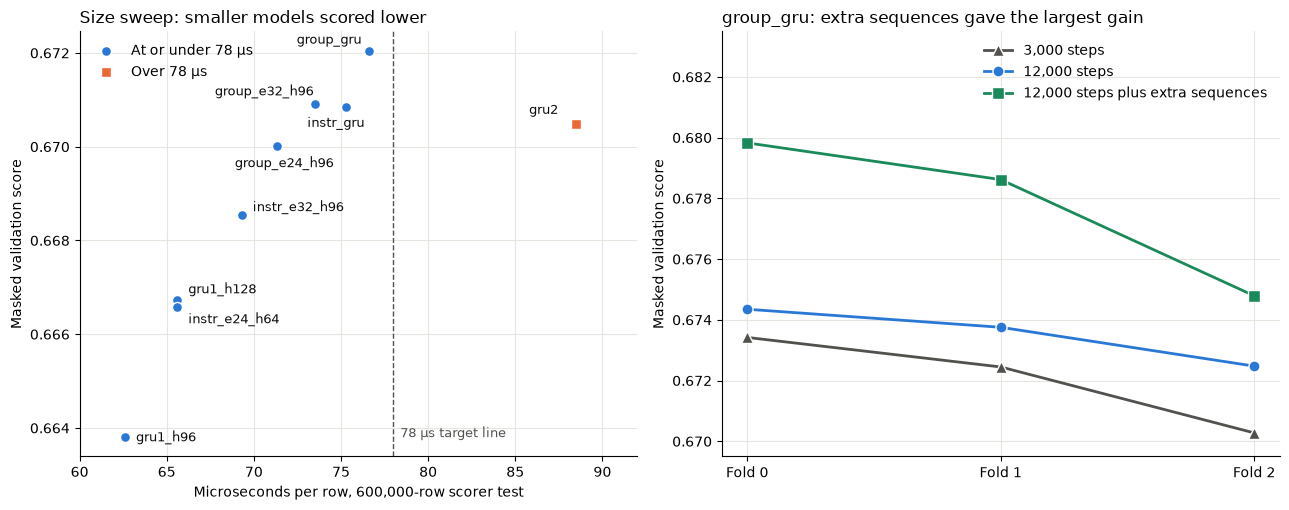

In [7]:
figure, (left, right) = plt.subplots(1, 2, figsize=(13, 5.2))

for name, color, marker, part in [('At or under 78 µs', BLUE, 'o', sweep[sweep['us_per_row'] <= SAFE_US]),
                                  ('Over 78 µs', ORANGE, 's', sweep[sweep['us_per_row'] > SAFE_US])]:
    left.scatter(part['us_per_row'], part['masked'], s=52, c=color, marker=marker, edgecolors='white', label=name, zorder=3)
offsets = {'group_e32_h96': (-72, 6), 'instr_gru': (-28, -14), 'group_gru': (-52, 5), 'group_e24_h96': (-30, -15),
           'instr_e24_h64': (8, -12), 'gru1_h128': (8, 5), 'instr_e32_h96': (8, 3), 'gru1_h96': (8, -3), 'gru2': (-34, 7)}
for key, row in sweep.iterrows():
    left.annotate(key, (row['us_per_row'], row['masked']), xytext=offsets.get(key, (6, 3)),
                  textcoords='offset points', fontsize=9, color=INK)
left.axvline(SAFE_US, color=MUTED, linewidth=1, linestyle='--')
left.annotate('78 µs target line', (SAFE_US, sweep['masked'].min()), xytext=(5, 0), textcoords='offset points', fontsize=9, color=MUTED)
left.set_xlim(60, 92)
left.set_xlabel('Microseconds per row, 600,000-row scorer test')
left.set_ylabel('Masked validation score')
left.set_title('Size sweep: smaller models scored lower', loc='left', fontsize=12)
left.legend(frameon=False, loc='upper left')

for tag, color, marker in [('r2', MUTED, '^'), ('r2_long', BLUE, 'o'), ('r2_long_extra', GREEN, 's')]:
    right.plot(masked.index, masked[tag], color=color, linewidth=2, marker=marker, markersize=8,
               markeredgecolor='white', label=LABELS[tag], zorder=3)
right.set_xticks(masked.index, [f'Fold {fold}' for fold in masked.index])
right.set_ylabel('Masked validation score')
right.set_title('group_gru: extra sequences gave the largest gain', loc='left', fontsize=12)
right.set_ylim(0.6695, 0.6835)
right.legend(frameon=False, loc='upper right')

for axis in (left, right):
    axis.grid(color='#e6e5e0', linewidth=0.8, zorder=0)
    axis.spines[['top', 'right']].set_visible(False)
figure.tight_layout()
plt.show()